# 🎯 Caso d'Uso 2: Il Motore di Ricerca Semantica

In [22]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd

# =====================================================================
# 1. PREPARAZIONE DEI DATI E DIZIONARIO (Simulazione Quora Question Pairs)
# =====================================================================
# Definiamo una Query utente e un Database di documenti
query = "Qual è il prezzo di questa vettura"

# Database: le frasi del dataset italiano classificate come ham (labels == 0), senza duplicati
df = pd.read_csv("datasets/italian.csv")
database = df.loc[df["labels"] == 0, "text"].drop_duplicates().tolist()
print(f"Documenti nel database: {len(database)}")

tutti_i_testi = [query] + database

# Tokenizzazione e Vocabolario basilare
parole = sorted(set(" ".join(tutti_i_testi).lower().split()))  # ordinato: indici stabili tra un'esecuzione e l'altra
vocabolario = {parola: i+1 for i, parola in enumerate(parole)}
vocabolario["<PAD>"] = 0
vocab_size = len(vocabolario)

MAX_LEN = 16  # le frasi ham sono lunghe in media ~13 parole

def text_to_indices(testo, vocabolario, max_len=MAX_LEN):
    indici = [vocabolario[p] for p in testo.lower().split() if p in vocabolario]
    if len(indici) < max_len:
        indici += [0] * (max_len - len(indici)) # Padding con 0
    else:
        indici = indici[:max_len]
    return torch.tensor([indici]) # Ritorna un tensore con dimensione Batch=1

# Convertiamo i testi in tensori pronti per le reti
t_query = text_to_indices(query, vocabolario)
t_db = torch.cat([text_to_indices(doc, vocabolario) for doc in database])  # un unico batch [N, MAX_LEN]


# =====================================================================
# 2. DEFINIZIONE DELLE ARCHITETTURE PER ESTRAZIONE EMBEDDING
# =====================================================================

# Modello Ricorrente (LSTM / GRU) configurato per sputare l'Embedding finale
class RecurrentEmbedder(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, rnn_type="LSTM"):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        if rnn_type == "LSTM":
            self.rnn = nn.LSTM(embedding_dim, hidden_dim, batch_first=True)
        elif rnn_type == "GRU":
            self.rnn = nn.GRU(embedding_dim, hidden_dim, batch_first=True)
            
    def get_embedding(self, text):
        # Esaminiamo il flusso senza calcolare i gradienti (siamo in inferenza)
        embedded = self.embedding(text)
        if isinstance(self.rnn, nn.LSTM):
            output, (hidden, cell) = self.rnn(embedded)
        else:
            output, hidden = self.rnn(embedded)
        
        # L'embedding della frase è l'hidden state generato all'ULTIMA PAROLA REALE del testo
        # Rappresenta il "collo di bottiglia" in cui è compressa la frase [0.5]
        # (non usiamo hidden[-1], che arriva dopo i token di padding: con molto padding
        # la rete converge allo stesso stato per tutte le frasi e gli embedding diventano identici)
        lunghezze = (text != 0).sum(dim=1).clamp(min=1)
        return output[torch.arange(text.size(0)), lunghezze - 1]

# Modello Transformer (Self-Attention) configurato per l'Embedding
class TransformerEmbedder(nn.Module):
    def __init__(self, vocab_size, embedding_dim, nhead, hidden_dim, num_layers, max_len=MAX_LEN):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.pos_embedding = nn.Embedding(max_len, embedding_dim)
        
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embedding_dim, nhead=nhead, dim_feedforward=hidden_dim, batch_first=True, activation='relu'
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        
    def get_embedding(self, text):
        batch_size, seq_len = text.size()
        pos = torch.arange(0, seq_len).unsqueeze(0).repeat(batch_size, 1).to(text.device)
        
        # Somma Semantica + Posizionale
        x = self.embedding(text) + self.pos_embedding(pos)
        features = self.transformer(x)
        
        # L'embedding della frase viene estratto facendo il Global Average Pooling [0.5]
        # della matrice di attenzione. Ogni parola ha interagito con le altre!
        # La media è calcolata solo sulle parole reali, escludendo le posizioni di padding
        maschera = (text != 0).unsqueeze(-1).float()
        return (features * maschera).sum(dim=1) / maschera.sum(dim=1).clamp(min=1)


# =====================================================================
# 3. PIPELINE DI CONFRONTO SEMANTICO (Cosine Similarity)
# =====================================================================
# Funzione matematica per calcolare l'angolo tra i vettori nello spazio geometrico
cosine_similarity = nn.CosineSimilarity(dim=1, eps=1e-6)

# Instanziamo i modelli con pesi fissati (In un progetto reale questi modelli verrebbero 
# prima pre-addestrati su coppie di frasi usando una Contrastive Loss / Cosine Embedding Loss)
torch.manual_seed(42)
modelli = {
    "Rete LSTM": RecurrentEmbedder(vocab_size, embedding_dim=16, hidden_dim=16, rnn_type="LSTM"),
    "Rete GRU": RecurrentEmbedder(vocab_size, embedding_dim=16, hidden_dim=16, rnn_type="GRU"),
    "Transformer": TransformerEmbedder(vocab_size, embedding_dim=16, nhead=2, hidden_dim=16, num_layers=1)
}

TOP_K = 5  # numero di documenti più simili da mostrare

print(f"QUERY UTENTE: '{query}'\n")

for nome, modello in modelli.items():
    modello.eval() # Modalità valutazione
    with torch.no_grad():
        # 1. Estraiamo il vettore (Embedding) della Query
        vec_query = modello.get_embedding(t_query)
        
        print(f"--- TOP {TOP_K} RISULTATI DI RICERCA CON: {nome} ---")
        # 2. Estraiamo in un colpo solo gli embedding di tutti i documenti del database
        vec_db = modello.get_embedding(t_db)
        
        # 3. Calcolo del punteggio di similarità con ogni documento (valori tra -1 e 1)
        scores = cosine_similarity(vec_query, vec_db)  # vec_query [1, D] viene confrontato con ogni riga di vec_db [N, D]
        
        # 4. Ordiniamo e mostriamo solo i documenti più vicini alla query
        migliori = torch.topk(scores, k=TOP_K)
        for score, i in zip(migliori.values, migliori.indices):
            print(f"Score: {score.item():+.4f} | Documento: '{database[i]}'")
    print("-" * 70)


Documenti nel database: 7263
QUERY UTENTE: 'Qual è il prezzo di questa vettura'

--- TOP 5 RISULTATI DI RICERCA CON: Rete LSTM ---
Score: +0.9367 | Documento: 'Buon compleanno! Ti invio una toratin expectation fs(ii).'
Score: +0.9225 | Documento: 'Il tempo oggi è abbastanza variabile con nuvoloni al mattino.'
Score: +0.9150 | Documento: 'Per migliorare la postura mentre si lavora al computer, è consigliabile fare stretching ogni ora.'
Score: +0.9150 | Documento: 'Scuola primaria 'Insieme per il futuro' organizza un evento di lettura.'
Score: +0.9063 | Documento: 'Ciao Marco, ti scrivo per chiederti se vuoi partecipare al progetto di volontariato questa settimana.'
----------------------------------------------------------------------
--- TOP 5 RISULTATI DI RICERCA CON: Rete GRU ---
Score: +0.9077 | Documento: 'Ricette per la cena veloci: pasta con pomodori passata e salsicce freschi.'
Score: +0.8815 | Documento: 'Ciao, ti mando il file PDF che abbiamo discusso ieri.'
Score: +0.8772 | D

## Baseline: TF-IDF + Cosine Similarity

Confronto con un metodo classico che non richiede addestramento: la similarità dipende solo dalle **parole in comune** tra query e documento, pesate per quanto sono rare nel database (IDF). 
Non riconosce i sinonimi: "vettura", "auto" e "macchina" sono per lui parole diverse.

In [23]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity as cosine_similarity_sparse

# =====================================================================
# BASELINE CLASSICA: TF-IDF + Cosine Similarity (nessun addestramento)
# =====================================================================
# Stop words italiane: parole molto comuni (articoli, preposizioni, pronomi...) che non portano significato
STOP_WORDS_IT = [
    'il', 'lo', 'la', 'le', 'gli', 'un', 'uno', 'una',
    'di', 'da', 'in', 'con', 'su', 'per', 'tra', 'fra',
    'del', 'dello', 'della', 'dei', 'degli', 'delle', 'al', 'allo', 'alla', 'ai', 'agli', 'alle',
    'dal', 'dallo', 'dalla', 'dai', 'dagli', 'dalle', 'nel', 'nello', 'nella', 'nei', 'negli', 'nelle',
    'sul', 'sullo', 'sulla', 'sui', 'sugli', 'sulle',
    'ed', 'ma', 'se', 'che', 'chi', 'non', 'come', 'anche', 'più',
    'mi', 'ti', 'ci', 'vi', 'si', 'ne', 'li',
    'qual', 'quale', 'questo', 'questa', 'quello', 'quella',
]

# Ogni documento diventa un vettore sparso: un peso per ogni parola del vocabolario,
# alto se la parola è frequente nel documento ma rara nel resto del database (IDF)
vectorizer = TfidfVectorizer(lowercase=True, stop_words=STOP_WORDS_IT)
matrice_db = vectorizer.fit_transform(database)   # [N documenti, V parole]
vettore_query = vectorizer.transform([query])     # [1, V]

# Parole della query che il TF-IDF conosce: le altre non contribuiscono alla similarità
vocab_tfidf = vectorizer.vocabulary_
parole_query = vectorizer.build_analyzer()(query)
print(f"Parole della query nel vocabolario TF-IDF: {[p for p in parole_query if p in vocab_tfidf]}")
print(f"Parole della query sconosciute:            {[p for p in parole_query if p not in vocab_tfidf]}\n")

scores_tfidf = cosine_similarity_sparse(vettore_query, matrice_db)[0]

print(f"--- TOP {TOP_K} RISULTATI DI RICERCA CON: TF-IDF ---")
for i in np.argsort(scores_tfidf)[::-1][:TOP_K]:
    print(f"Score: {scores_tfidf[i]:+.4f} | Documento: '{database[i]}'")

Parole della query nel vocabolario TF-IDF: ['prezzo']
Parole della query sconosciute:            ['vettura']

--- TOP 5 RISULTATI DI RICERCA CON: TF-IDF ---
Score: +0.4271 | Documento: 'Ho comprato un nuovo smartphone con un ottimo rapporto qualità-prezzo.'
Score: +0.4038 | Documento: 'Takobiki, sushi giapponese a prezzo speciale!'
Score: +0.3929 | Documento: 'Ciao! Sto acquistando un nuovo smartphone a prezzo scontato.'
Score: +0.3865 | Documento: 'Il mercato locale offre prodotti freschi a buon prezzo questo fine settimana.'
Score: +0.3791 | Documento: 'Recensione: Il nuovo smartphone X10 è davvero valido per il prezzo?'


## Modello pre-addestrato: Sentence-Transformer multilingue

Stessa architettura di base del nostro `TransformerEmbedder`, ma con due differenze decisive:

1. **Pre-training** su enormi quantità di testo in oltre 50 lingue, italiano compreso: impara che "vettura", "auto" e "macchina" compaiono in contesti simili.
2. **Addestramento contrastivo** su milioni di coppie di parafrasi: frasi con lo stesso significato vengono avvicinate nello spazio degli embedding.

Il primo avvio scarica il modello (~470 MB).

In [24]:
%%capture
%pip install -q sentence-transformers

In [25]:
import time
from sentence_transformers import SentenceTransformer

# =====================================================================
# MODELLO PRE-ADDESTRATO: Sentence-Transformer multilingue
# =====================================================================
# Transformer (12 layer, embedding a 384 dimensioni) pre-addestrato su testi in 50+ lingue
# e poi addestrato su milioni di coppie di parafrasi con una loss contrastiva:
# frasi con lo stesso significato -> vettori vicini, anche se usano parole diverse
NOME_MODELLO = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
device_st = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"
modello_st = SentenceTransformer(NOME_MODELLO, device=device_st)

# Embedding di tutto il database (calcolato una volta sola, poi riutilizzabile per ogni query)
inizio = time.perf_counter()
vec_db_st = modello_st.encode(database, batch_size=128, convert_to_tensor=True, normalize_embeddings=True)
print(f"Embedding di {len(database)} documenti calcolati in {time.perf_counter() - inizio:.1f}s su {device_st}\n")

vec_query_st = modello_st.encode([query], convert_to_tensor=True, normalize_embeddings=True)

# Con vettori normalizzati la similarità del coseno è un semplice prodotto scalare
scores_st = (vec_query_st @ vec_db_st.T)[0]

print(f"--- TOP {TOP_K} RISULTATI DI RICERCA CON: Sentence-Transformer pre-addestrato ---")
migliori = torch.topk(scores_st, k=TOP_K)
for score, i in zip(migliori.values, migliori.indices):
    print(f"Score: {score.item():+.4f} | Documento: '{database[i]}'")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 15650.97it/s]


Embedding di 7263 documenti calcolati in 2.7s su mps

--- TOP 5 RISULTATI DI RICERCA CON: Sentence-Transformer pre-addestrato ---
Score: +0.6497 | Documento: 'Rappel auto: il tuo modello è interessato? Controlla il numero di telaio qui.'
Score: +0.6209 | Documento: 'Ritirati a lungo: i costi per la manutenzione dell’auto sono stati aggiornati a 35€/mese. Conferma la tua scelta.'
Score: +0.5385 | Documento: 'Scheda Prodotto: Elettrodomestico A.30 Pro White - Prezzo 1.150€ - Descrizione: Motore a 5 cavalli, Efficienza energetica A+++ - Disponibilità: 15/09/2023'
Score: +0.5311 | Documento: 'Ho appena comprato una macchina nuova, è davvero bella.'
Score: +0.5246 | Documento: 'Potreste inviarmi il prezzo totale per l'installazione del sistema di riscaldamento?'


## Tempi di ricerca: Sentence-Transformer vs TF-IDF

Separiamo le fasi che avvengono **una volta sola** (caricamento del modello, embedding del database) da quella che avviene **a ogni query**. 
I tempi della ricerca sono la mediana di 50 ripetizioni.

In [26]:
# =====================================================================
# TEMPI DI RICERCA: Sentence-Transformer (GPU e CPU) vs TF-IDF
# =====================================================================
def mediana_ms(funzione, ripetizioni=50):
    """Latenza mediana in ms di `funzione` (dopo una chiamata di warm-up)."""
    funzione()
    tempi = []
    for _ in range(ripetizioni):
        inizio = time.perf_counter()
        funzione()
        tempi.append(time.perf_counter() - inizio)
    return np.median(tempi) * 1000

def misura_sentence_transformer(device_misura):
    inizio = time.perf_counter()
    modello = SentenceTransformer(NOME_MODELLO, device=device_misura)
    t_caricamento = time.perf_counter() - inizio

    inizio = time.perf_counter()
    vec_db = modello.encode(database, batch_size=128, convert_to_tensor=True,
                            normalize_embeddings=True, show_progress_bar=False)
    t_database = time.perf_counter() - inizio

    def embedding_query():
        # .cpu() attende la fine del calcolo sulla GPU: il tempo misurato è reale
        return modello.encode([query], convert_to_tensor=True, normalize_embeddings=True).cpu()

    def ricerca():
        vec_query = modello.encode([query], convert_to_tensor=True, normalize_embeddings=True)
        return torch.topk((vec_query @ vec_db.T)[0], k=TOP_K).indices.tolist()

    t_ricerca, t_query = mediana_ms(ricerca), mediana_ms(embedding_query)
    return {
        "Caricamento del modello": f"{t_caricamento:.1f} s",
        f"Embedding del database ({len(database)} frasi)": f"{t_database:.1f} s",
        "Ricerca (una query)": f"{t_ricerca:.2f} ms",
        "  di cui: embedding della query": f"{t_query:.2f} ms",
        f"  di cui: similarità + top {TOP_K}": f"{t_ricerca - t_query:.2f} ms",
    }

def misura_tfidf():
    inizio = time.perf_counter()
    vectorizer_misura = TfidfVectorizer(lowercase=True, stop_words=STOP_WORDS_IT)
    matrice = vectorizer_misura.fit_transform(database)
    t_database = time.perf_counter() - inizio

    def embedding_query():
        return vectorizer_misura.transform([query])

    def ricerca():
        scores = cosine_similarity_sparse(vectorizer_misura.transform([query]), matrice)[0]
        return np.argsort(scores)[::-1][:TOP_K]

    t_ricerca, t_query = mediana_ms(ricerca), mediana_ms(embedding_query)
    return {
        "Caricamento del modello": "—",
        f"Embedding del database ({len(database)} frasi)": f"{t_database:.2f} s",
        "Ricerca (una query)": f"{t_ricerca:.2f} ms",
        "  di cui: embedding della query": f"{t_query:.2f} ms",
        f"  di cui: similarità + top {TOP_K}": f"{t_ricerca - t_query:.2f} ms",
    }

tempi = {}
if device_st != "cpu":
    tempi[f"Sentence-Transformer ({device_st})"] = misura_sentence_transformer(device_st)
tempi["Sentence-Transformer (cpu)"] = misura_sentence_transformer("cpu")
tempi["TF-IDF"] = misura_tfidf()

tabella_tempi = pd.DataFrame(tempi)
tabella_tempi["Quando avviene"] = ["una volta, all'avvio", "una volta, o quando cambiano i documenti",
                                   "a ogni query", "", ""]
tabella_tempi.index.name = "Fase"
display(tabella_tempi)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 14133.47it/s]


,Sentence-Transformer (mps),Sentence-Transformer (cpu),TF-IDF,Quando avviene
Fase,,,,
Caricamento del modello,3.5 s,3.2 s,—,"una volta, all'avvio"
Embedding del database (7263 frasi),2.9 s,6.0 s,0.03 s,"una volta, o quando cambiano i documenti"
Ricerca (una query),5.82 ms,6.50 ms,0.53 ms,a ogni query
di cui: embedding della query,5.58 ms,6.28 ms,0.12 ms,
di cui: similarità + top 5,0.24 ms,0.21 ms,0.41 ms,


## Valutazione della qualità della ricerca: LLM come giudice

Per stimare quanto sono pertinenti i risultati serve una verità di riferimento. La costruiamo così:

1. **Query di valutazione**: 20 query su argomenti presenti nel database.
2. **Pooling**: per ogni query si raccolgono i primi 5 risultati di *tutti* i metodi; le coppie (query, documento) distinte vengono giudicate una sola volta.
3. **Giudice**: un LLM locale (`gemma3:12b` via Ollama) assegna a ogni coppia un voto di pertinenza: 0 = non pertinente, 1 = parzialmente, 2 = pienamente pertinente.
4. **Metriche** per metodo, mediate sulle query, con intervallo di confidenza al 95%:
   - *P@5*: quota dei primi 5 risultati almeno parzialmente pertinenti (voto ≥ 1)
   - *MRR*: 1 / posizione del primo risultato pertinente
5. **Validazione del giudice**: su un campione annotato a mano si misura l'accordo tra persona e LLM (kappa di Cohen).

In [27]:
# =====================================================================
# 1. QUERY DI VALUTAZIONE E RISULTATI DI OGNI METODO (pooling)
# =====================================================================
# Query su argomenti presenti nel database, formulate quando possibile con parole diverse
# da quelle dei documenti (per non avvantaggiare i metodi puramente lessicali come il TF-IDF)
QUERY_VALUTAZIONE = [
    "Qual è il prezzo di questa vettura",
    "Che tempo farà domani?",
    "Com'è finita la partita di pallone?",
    "Mi consigli un romanzo da leggere?",
    "Come si prepara un dolce tipico italiano",
    "Il mezzo pubblico è in ritardo",
    "Incontro di lavoro con i colleghi",
    "Ho smarrito il cellulare",
    "Quando arriva la mia spedizione?",
    "Restituzione dei soldi per un acquisto",
    "Partire in vacanza all'estero",
    "Camminare all'aria aperta nel verde",
    "Una pellicola vista al cinema",
    "Imparare l'inglese",
    "La connessione a internet di casa non funziona",
    "Cerco un nuovo impiego",
    "Festeggiare il compleanno di un amico",
    "Esposizione di quadri al museo",
    "Mangiare sano e fare attività fisica",
    "Quante persone sono senza lavoro in Italia",
]

def cerca_tfidf(q, k):
    scores = cosine_similarity_sparse(vectorizer.transform([q]), matrice_db)[0]
    return np.argsort(scores)[::-1][:k].tolist()

# Embedding del database per i modelli non addestrati (calcolati una volta sola)
with torch.no_grad():
    vec_db_modelli = {nome: m.eval().get_embedding(t_db) for nome, m in modelli.items()}

def cerca_rete(nome, q, k):
    with torch.no_grad():
        vec_q = modelli[nome].get_embedding(text_to_indices(q, vocabolario))
        return torch.topk(cosine_similarity(vec_q, vec_db_modelli[nome]), k=k).indices.tolist()

def cerca_sentence_transformer(q, k):
    vec_q = modello_st.encode([q], convert_to_tensor=True, normalize_embeddings=True)
    return torch.topk((vec_q @ vec_db_st.T)[0], k=k).indices.tolist()

METODI = {
    "TF-IDF": cerca_tfidf,
    **{f"{nome} (non addestrata)": (lambda q, k, nome=nome: cerca_rete(nome, q, k)) for nome in modelli},
    "Sentence-Transformer": cerca_sentence_transformer,
}

righe = []
for q in QUERY_VALUTAZIONE:
    for metodo, cerca in METODI.items():
        for rank, doc_id in enumerate(cerca(q, TOP_K), start=1):
            righe.append({"query": q, "metodo": metodo, "rank": rank, "doc_id": doc_id})
risultati_ricerca = pd.DataFrame(righe)

# Pool: coppie (query, documento) distinte da giudicare, indipendentemente dal metodo che le ha trovate
pool = risultati_ricerca[["query", "doc_id"]].drop_duplicates().reset_index(drop=True)
print(f"{len(QUERY_VALUTAZIONE)} query x {len(METODI)} metodi x top {TOP_K} = {len(risultati_ricerca)} risultati")
print(f"Coppie (query, documento) distinte da giudicare: {len(pool)}")

20 query x 5 metodi x top 5 = 500 risultati
Coppie (query, documento) distinte da giudicare: 487


Richiede Ollama in esecuzione con il modello scaricato: `ollama pull gemma3:12b`. I giudizi vengono salvati in `datasets/giudizi_llm.csv` e non vengono ricalcolati alle esecuzioni successive.

In [28]:
import json
import os
import urllib.request

# =====================================================================
# 2. GIUDIZI DI PERTINENZA CON UN LLM LOCALE (Ollama)
# =====================================================================
OLLAMA_URL = "http://localhost:11434/api/chat"
MODELLO_GIUDICE = "gemma3:12b"
FILE_GIUDIZI = "datasets/giudizi_llm.csv"  # cache: i giudizi già dati non vengono ricalcolati

PROMPT_SISTEMA = (
    "Sei un valutatore esperto di sistemi di ricerca. "
    "Devi giudicare quanto un documento è pertinente rispetto a una query di ricerca, "
    "considerando il significato e non solo le parole in comune."
)

def prompt_utente(query, documento):
    return (
        f"Query: {query}\n"
        f"Documento: {documento}\n\n"
        "Scala di pertinenza:\n"
        "2 = pienamente pertinente: il documento tratta proprio l'argomento della query\n"
        "1 = parzialmente pertinente: tratta un argomento collegato o solo una parte della query\n"
        "0 = non pertinente\n\n"
        'Rispondi solo con un JSON nel formato {"voto": 0, 1 o 2}.'
    )

def giudica(query, documento):
    richiesta = {
        "model": MODELLO_GIUDICE,
        "messages": [
            {"role": "system", "content": PROMPT_SISTEMA},
            {"role": "user", "content": prompt_utente(query, documento)},
        ],
        # Output vincolato a uno schema JSON e temperatura 0 per giudizi riproducibili
        "format": {"type": "object", "properties": {"voto": {"type": "integer", "enum": [0, 1, 2]}},
                   "required": ["voto"]},
        "options": {"temperature": 0},
        "stream": False,
    }
    req = urllib.request.Request(OLLAMA_URL, data=json.dumps(richiesta).encode(),
                                 headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=300) as risposta:
        contenuto = json.loads(risposta.read())["message"]["content"]
    return int(json.loads(contenuto)["voto"])

# Carichiamo i giudizi già presenti in cache
if os.path.exists(FILE_GIUDIZI):
    giudizi = pd.read_csv(FILE_GIUDIZI)
else:
    giudizi = pd.DataFrame(columns=["query", "doc_id", "voto"])
gia_giudicati = set(zip(giudizi["query"], giudizi["doc_id"]))
da_giudicare = [(q, d) for q, d in zip(pool["query"], pool["doc_id"]) if (q, d) not in gia_giudicati]
print(f"Giudizi in cache: {len(gia_giudicati)} | da calcolare: {len(da_giudicare)}")

inizio = time.perf_counter()
nuovi = []
for n, (q, doc_id) in enumerate(da_giudicare, start=1):
    nuovi.append({"query": q, "doc_id": doc_id, "voto": giudica(q, database[doc_id])})
    if n % 25 == 0 or n == len(da_giudicare):
        # Salviamo periodicamente: se l'esecuzione si interrompe, non si perde il lavoro fatto
        giudizi = pd.concat([giudizi, pd.DataFrame(nuovi)], ignore_index=True)
        giudizi.to_csv(FILE_GIUDIZI, index=False)
        nuovi = []
        print(f"  {n}/{len(da_giudicare)} giudizi ({time.perf_counter() - inizio:.0f}s)")

giudizi["doc_id"] = giudizi["doc_id"].astype(int)
giudizi["voto"] = giudizi["voto"].astype(int)
print("\nDistribuzione dei voti:", giudizi["voto"].value_counts().sort_index().to_dict())

Giudizi in cache: 1304 | da calcolare: 0

Distribuzione dei voti: {0: 1126, 1: 117, 2: 61}


In [29]:
# =====================================================================
# 3. METRICHE: Precision@5 e MRR
# =====================================================================
valutati = risultati_ricerca.merge(giudizi, on=["query", "doc_id"], how="left")
assert valutati["voto"].notna().all(), "Mancano dei giudizi: riesegui la cella precedente"

def metriche_query(gruppo):
    voti = gruppo.sort_values("rank")["voto"].tolist()
    pertinenti = [v >= 1 for v in voti]  # pertinente = almeno parzialmente pertinente
    return pd.Series({
        "P@5": np.mean(pertinenti),                                                 # quota di risultati pertinenti
        "MRR": next((1 / r for r, p in enumerate(pertinenti, start=1) if p), 0.0),  # 1 / posizione del primo pertinente
    })

METRICHE = ["P@5", "MRR"]
per_query = valutati.groupby(["query", "metodo"]).apply(metriche_query, include_groups=False)
tabella_metriche = per_query.groupby("metodo").mean().sort_values("P@5", ascending=False)
print(f"--- QUALITÀ DELLA RICERCA (media su {len(QUERY_VALUTAZIONE)} query, giudice: {MODELLO_GIUDICE}) ---")
display(tabella_metriche.round(3))

--- QUALITÀ DELLA RICERCA (media su 20 query, giudice: gemma3:12b) ---


,P@5,MRR
metodo,,
Sentence-Transformer,0.81,0.917
TF-IDF,0.58,0.788
Rete LSTM (non addestrata),0.09,0.217
Rete GRU (non addestrata),0.07,0.146
Transformer (non addestrata),0.01,0.012


In [30]:
from sklearn.metrics import cohen_kappa_score

# =====================================================================
# 4. VALIDAZIONE DEL GIUDICE: accordo LLM vs annotazione umana
# =====================================================================
# Un campione casuale di coppie viene annotato a mano (colonna "voto_umano", stessa scala 0/1/2).
# Se l'accordo con l'LLM è alto, i suoi giudizi sul resto del pool sono considerati affidabili.
FILE_CAMPIONE = "datasets/campione_validazione_giudice.csv"
N_CAMPIONE = 50

if not os.path.exists(FILE_CAMPIONE):
    campione = giudizi.sample(N_CAMPIONE, random_state=42)[["query", "doc_id"]].copy()
    campione["documento"] = [database[i] for i in campione["doc_id"]]
    campione["voto_umano"] = ""  # da compilare a mano (0, 1 o 2), SENZA guardare il voto dell'LLM
    campione.to_csv(FILE_CAMPIONE, index=False)
    print(f"Creato {FILE_CAMPIONE}: compila la colonna 'voto_umano' e riesegui questa cella.")
else:
    campione = pd.read_csv(FILE_CAMPIONE).merge(giudizi, on=["query", "doc_id"])
    annotati = campione[pd.to_numeric(campione["voto_umano"], errors="coerce").notna()]
    if len(annotati) == 0:
        print(f"Nessun voto umano in {FILE_CAMPIONE}: compila la colonna 'voto_umano' e riesegui questa cella.")
    else:
        umano, llm = annotati["voto_umano"].astype(int), annotati["voto"].astype(int)
        print(f"Coppie annotate: {len(annotati)}/{len(campione)}")
        print(f"Accordo esatto:              {(umano == llm).mean():.1%}")
        print(f"Accordo pertinente/non (≥1): {((umano >= 1) == (llm >= 1)).mean():.1%}")
        # Kappa di Cohen pesato: accordo corretto per il caso, penalizza di più gli errori 0 <-> 2
        print(f"Kappa di Cohen (pesato):     {cohen_kappa_score(umano, llm, weights='quadratic'):.3f}"
              "  (> 0.6 buono, > 0.8 ottimo)")
        display(pd.crosstab(umano, llm, rownames=["Umano"], colnames=[f"LLM ({MODELLO_GIUDICE})"]))

Coppie annotate: 50/50
Accordo esatto:              88.0%
Accordo pertinente/non (≥1): 92.0%
Kappa di Cohen (pesato):     0.802  (> 0.6 buono, > 0.8 ottimo)


LLM (gemma3:12b),0,1,2
Umano,,,
0,39,2,0
1,2,3,1
2,0,1,2


## Valutazione dei modelli

Un motore di ricerca non ha un'etichetta giusta/sbagliata come un classificatore: per ogni query restituisce una **lista ordinata** di documenti, e la qualità dipende da *quanti* sono pertinenti e da *dove* compaiono nella lista. Per misurarla servono dei **giudizi di pertinenza** (in gergo *qrels*): per ogni coppia (query, documento), quanto il documento risponde alla query.

### Il procedimento
1. **20 query di valutazione** su argomenti presenti nel database (meteo, calcio, libri, cucina, trasporti, lavoro…), formulate quando possibile con parole *diverse* da quelle dei documenti: "pellicola" invece di "film", "vettura" invece di "auto". Così si mette alla prova la comprensione del significato, non la semplice corrispondenza di parole.
2. **LLM come giudice**: un modello linguistico locale (`gemma3:12b`, eseguito con Ollama) legge query e documento e assegna un voto su una scala a tre livelli:
   - **2** = pienamente pertinente: il documento tratta proprio l'argomento della query
   - **1** = parzialmente pertinente: argomento collegato, o solo una parte della query
   - **0** = non pertinente

   Il giudice lavora con temperatura 0 e output vincolato a un JSON, per avere giudizi riproducibili.
3. **Validazione del giudice**: un LLM può sbagliare, quindi su un campione casuale di 50 coppie il voto viene dato anche da un secondo annotatore, *senza* vedere il voto dell'LLM, e si misura l'accordo tra i due.

### Le metriche
Entrambe si calcolano per ogni query sui primi *k* = 5 risultati, e poi si fa la media sulle 20 query. Un risultato è considerato **pertinente** se ha voto ≥ 1 (almeno parzialmente pertinente).

| Metrica | Cosa misura | Come si legge |
|---|---|---|
| **P@5** (Precision at 5) | Quota dei primi 5 risultati che sono pertinenti | 0.8 = in media 4 risultati su 5 sono utili |
| **MRR** (Mean Reciprocal Rank) | 1 / posizione del primo risultato pertinente: 1 se è il primo, 0.5 se è il secondo, 0.33 se è il terzo… 0 se non ce n'è nessuno | Quanto in fretta l'utente trova qualcosa di utile |

Le due metriche si completano: **P@5** dice *quanti* risultati utili ci sono nella prima pagina, **MRR** dice *quanto in alto* compare il primo. Un metodo può avere un MRR alto (il primo risultato è giusto) ma un P@5 basso (gli altri quattro no).

### Intervallo di confidenza al 95%
Con sole 20 query la media di una metrica dipende molto da quali query sono state scelte. Per stimare questa incertezza si usa il **bootstrap**: si estraggono 20 query a caso *con reinserimento* (alcune ripetute, altre escluse), si ricalcola la media, e si ripete 2000 volte. L'intervallo tra il 2.5° e il 97.5° percentile di queste 2000 medie è l'**intervallo di confidenza al 95%**. Se gli intervalli di due metodi non si sovrappongono, la differenza tra i due è robusta rispetto alla scelta delle query.

### Affidabilità del giudice
Sulle 50 coppie del campione, i voti dell'LLM sono stati confrontati con quelli di un secondo annotatore indipendente (**Claude**, modello di Anthropic, che ha votato senza vedere i voti dell'LLM). Risultato: accordo esatto **88%**, accordo pertinente/non pertinente **92%**, **kappa di Cohen pesato 0.80** (> 0.8 è considerato ottimo). I disaccordi riguardano casi limite fra voti adiacenti (0↔1, 1↔2), mai fra 0 e 2.


### Limiti della valutazione
- **20 query** sono poche e le differenze tra metodi potrebbero non essere significative. Per questo tabella e grafici riportano l'intervallo di confidenza al 95%.

--- QUALITÀ DELLA RICERCA (media su 20 query, top 5, giudice: gemma3:12b) ---


,P@5,P@5 IC 95%,MRR,MRR IC 95%
Metodo,,,,
Sentence-Transformer,0.81,0.68 – 0.93,0.917,0.78 – 1.00
TF-IDF,0.58,0.44 – 0.71,0.788,0.64 – 0.93
Rete LSTM (non addestrata),0.09,0.02 – 0.18,0.217,0.07 – 0.42
Rete GRU (non addestrata),0.07,0.02 – 0.13,0.146,0.03 – 0.30
Transformer (non addestrata),0.01,0.00 – 0.03,0.012,0.00 – 0.04


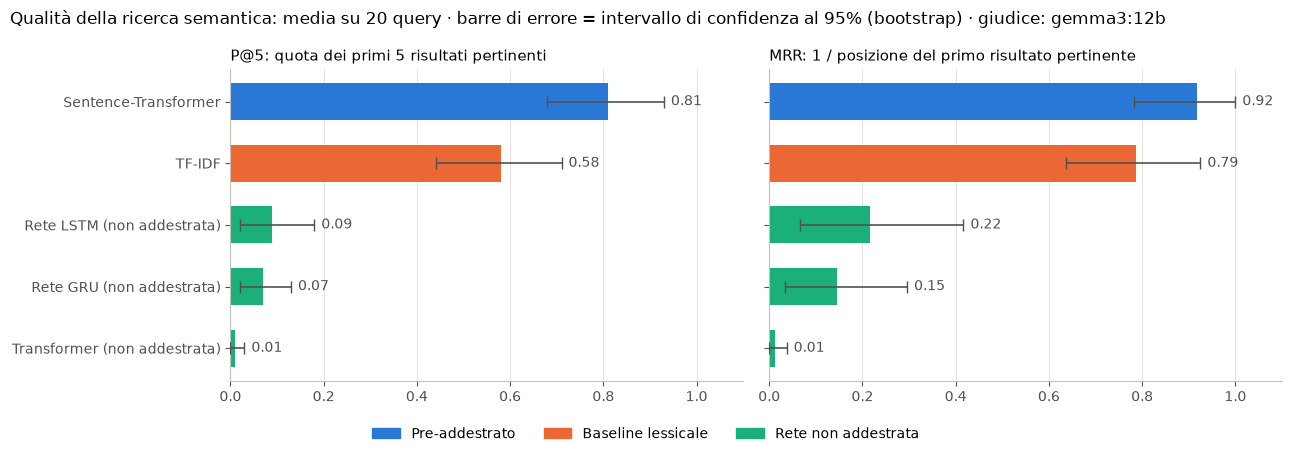

In [31]:
import matplotlib.pyplot as plt

# =====================================================================
# 5. RIEPILOGO: P@5 e MRR con intervallo di confidenza al 95%
# =====================================================================
# Intervallo di confidenza al 95% con bootstrap sulle query: ricampioniamo le 20 query
# con reinserimento, ricalcoliamo la media 2000 volte e prendiamo i percentili 2.5 e 97.5
rng = np.random.default_rng(42)
indici_bootstrap = rng.integers(0, len(QUERY_VALUTAZIONE), size=(2000, len(QUERY_VALUTAZIONE)))
ic_basso, ic_alto = {}, {}
for metrica in METRICHE:
    valori_query = per_query[metrica].unstack("metodo")  # righe = query, colonne = metodi
    medie = np.stack([valori_query.values[idx].mean(axis=0) for idx in indici_bootstrap])
    ic_basso[metrica] = pd.Series(np.percentile(medie, 2.5, axis=0), index=valori_query.columns)
    ic_alto[metrica] = pd.Series(np.percentile(medie, 97.5, axis=0), index=valori_query.columns)

tabella_riepilogo = pd.DataFrame(index=tabella_metriche.index)
for metrica in METRICHE:
    tabella_riepilogo[metrica] = tabella_metriche[metrica].round(3)
    tabella_riepilogo[f"{metrica} IC 95%"] = [f"{ic_basso[metrica][m]:.2f} – {ic_alto[metrica][m]:.2f}"
                                              for m in tabella_metriche.index]
tabella_riepilogo.index.name = "Metodo"
print(f"--- QUALITÀ DELLA RICERCA (media su {len(QUERY_VALUTAZIONE)} query, top {TOP_K}, giudice: {MODELLO_GIUDICE}) ---")
display(tabella_riepilogo)

# --- Istogrammi (barre orizzontali) di P@5 e MRR con intervallo di confidenza ---
FAMIGLIE = {  # colore per famiglia di metodo
    "Pre-addestrato": "#2a78d6",
    "Baseline lessicale": "#eb6834",
    "Rete non addestrata": "#1baf7a",
}
def famiglia(metodo):
    if metodo == "Sentence-Transformer":
        return "Pre-addestrato"
    return "Baseline lessicale" if metodo == "TF-IDF" else "Rete non addestrata"

COLORE_TESTO = "#52514e"
ordine = tabella_metriche.sort_values("P@5").index  # il migliore in alto
DESCRIZIONI = {
    "P@5": "P@5: quota dei primi 5 risultati pertinenti",
    "MRR": "MRR: 1 / posizione del primo risultato pertinente",
}

fig, assi = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, metrica in zip(assi, METRICHE):
    valori = tabella_metriche.loc[ordine, metrica]
    basso, alto = ic_basso[metrica][ordine], ic_alto[metrica][ordine]
    ax.barh(ordine, valori, height=0.6, color=[FAMIGLIE[famiglia(m)] for m in ordine], zorder=2)
    ax.errorbar(valori, ordine, xerr=[valori - basso, alto - valori],
                fmt="none", ecolor=COLORE_TESTO, elinewidth=1.2, capsize=4, zorder=3)
    for y, (m, v) in enumerate(valori.items()):
        ax.text(alto[m] + 0.015, y, f"{v:.2f}", va="center", fontsize=10, color=COLORE_TESTO)

    ax.set_xlim(0, 1.1)
    ax.set_title(DESCRIZIONI[metrica], loc="left", fontsize=11)
    ax.grid(True, axis="x", color="#e4e3df", linewidth=0.8, zorder=0)
    for lato in ("top", "right"):
        ax.spines[lato].set_visible(False)
    for lato in ("left", "bottom"):
        ax.spines[lato].set_color("#c3c2b7")
    ax.tick_params(colors=COLORE_TESTO)

fig.suptitle(f"Qualità della ricerca semantica: media su {len(QUERY_VALUTAZIONE)} query · "
             f"barre di errore = intervallo di confidenza al 95% (bootstrap) · giudice: {MODELLO_GIUDICE}",
             x=0.01, ha="left", fontsize=12)

# Legenda fuori dai grafici
gestori = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAMIGLIE.values()]
fig.legend(gestori, FAMIGLIE.keys(), loc="lower center", ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()